# Four-level laser dynamics

This notebook works through the laser rate equations with `lasersim`:

1. the light-current (L-I) curve and gain clamping,
2. turn-on spiking and relaxation oscillations,
3. a Q-switched giant pulse compared with the analytic theory,
4. choosing the output coupler (Rigrod analysis),
5. the photon lifetime and mode spacing of a real cavity.

Sections 1–3 use normalised units: time in units of the upper-level lifetime τ, and densities in units of 1/(Gτ).

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import lasersim as ls

laser = ls.FourLevelLaser(tau=1.0, tau_p=1e-3, G=1.0, beta=1e-5)
print(f"N_th = {laser.N_th:g}, P_th = {laser.P_th:g}")

N_th = 1000, P_th = 1000


## 1. L-I curve and gain clamping

Spontaneous seeding (β = 1e-5) rounds off the threshold. Above it, the inversion stays clamped at $N_{th}$.

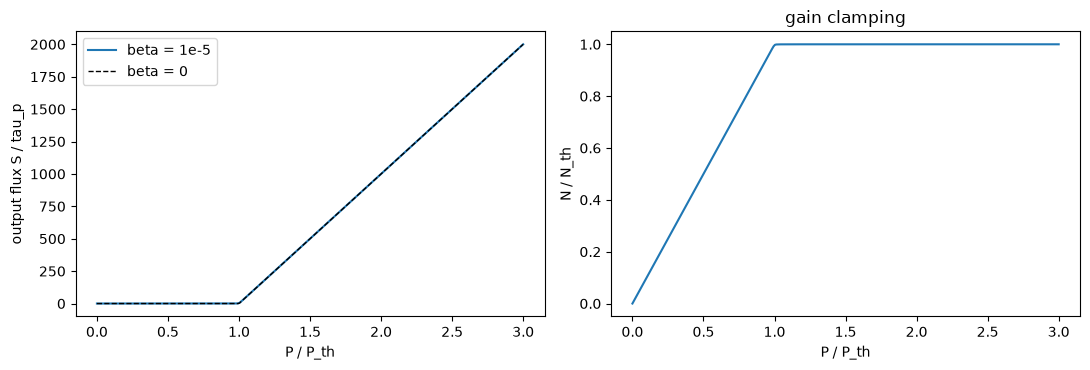

In [2]:
P = np.linspace(0, 3 * laser.P_th, 300)
ss = np.array([laser.steady_state(p) for p in P])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(P / laser.P_th, ss[:, 1] / laser.tau_p, label="beta = 1e-5")
axes[0].plot(P / laser.P_th, np.clip(P - laser.P_th, 0, None), "k--", lw=1, label="beta = 0")
axes[0].set_xlabel("P / P_th"); axes[0].set_ylabel("output flux S / tau_p"); axes[0].legend()
axes[1].plot(P / laser.P_th, ss[:, 0] / laser.N_th)
axes[1].set_xlabel("P / P_th"); axes[1].set_ylabel("N / N_th"); axes[1].set_title("gain clamping")
plt.tight_layout(); plt.show()

## 2. Turn-on and relaxation oscillations

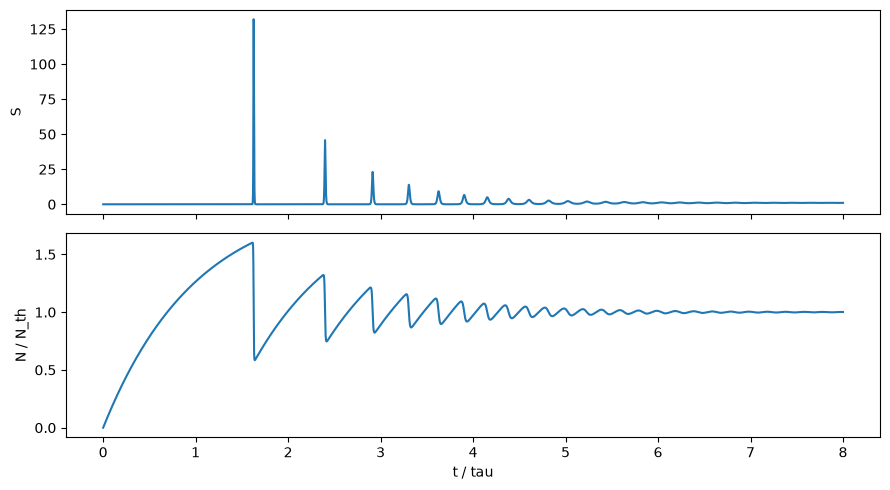

predicted damped frequency 31.61, measured 31.50 (rad per tau)


In [3]:
ideal = ls.FourLevelLaser(tau=1.0, tau_p=1e-3, G=1.0)
P2 = 2 * ideal.P_th
tr = ideal.simulate(P2, t_end=8.0, S0=1e-6, n_points=8000)
w_r, gam = ideal.relaxation_oscillation(P2)
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(tr.t, tr.S); ax[0].set_ylabel("S")
ax[1].plot(tr.t, tr.N / ideal.N_th); ax[1].set_ylabel("N / N_th"); ax[1].set_xlabel("t / tau")
plt.tight_layout(); plt.show()
print(f"predicted damped frequency {np.sqrt(w_r**2 - gam**2):.2f}, measured {ideal.measured_oscillation_frequency(tr):.2f} (rad per tau)")

## 3. Q-switched pulse

The inversion is stored at three times threshold and then the cavity Q is switched high.

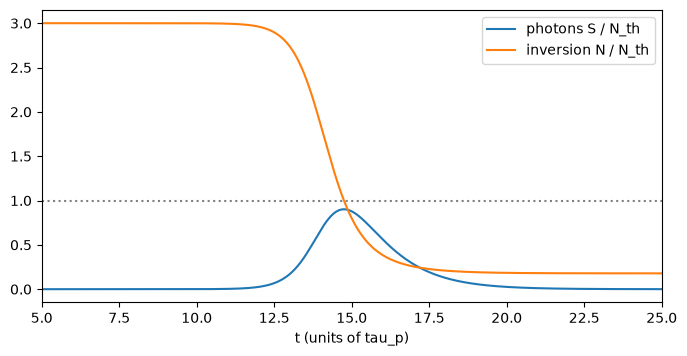

peak S: simulated 901.4, theory 901.4
energy extraction: simulated 0.9405, theory 0.9405


In [4]:
qs = ls.FourLevelLaser(tau=1e6, tau_p=1e-3, G=1.0)
Ni = 3 * qs.N_th
tr = qs.q_switch(Ni, t_end=0.06, n_points=60000)
plt.figure(figsize=(8, 3.8))
plt.plot(tr.t * 1e3, tr.S / qs.N_th, label="photons S / N_th")
plt.plot(tr.t * 1e3, tr.N / qs.N_th, label="inversion N / N_th")
plt.axhline(1, ls=":", c="gray")
plt.xlim(5, 25); plt.xlabel("t (units of tau_p)"); plt.legend(); plt.show()
print(f"peak S: simulated {tr.S.max():.1f}, theory {ls.qswitch_peak_photons(Ni, qs.N_th):.1f}")
print(f"energy extraction: simulated {1 - tr.N[-1]/Ni:.4f}, theory {ls.qswitch_extraction_efficiency(Ni, qs.N_th):.4f}")

## 4. Choosing the output coupler

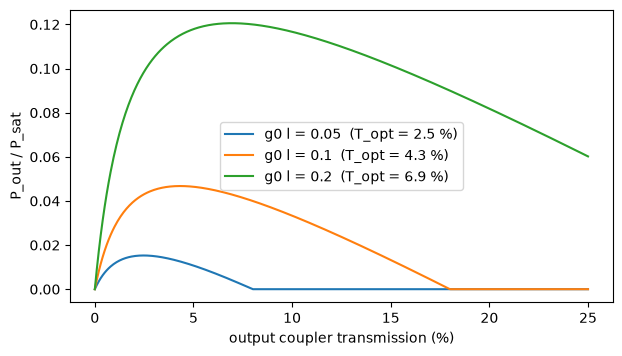

In [5]:
T = np.linspace(0, 0.25, 500)
plt.figure(figsize=(7, 3.8))
for g0l in (0.05, 0.1, 0.2):
    p = ls.rigrod_output(T, g0l, internal_loss=0.02)
    t_opt = ls.optimal_output_coupling(g0l, 0.02)
    plt.plot(T * 100, p, label=f"g0 l = {g0l}  (T_opt = {100 * t_opt:.1f} %)")
plt.xlabel("output coupler transmission (%)"); plt.ylabel("P_out / P_sat"); plt.legend(); plt.show()

## 5. A real cavity: 30 cm, R1 = 99.9 %, R2 = 95 %

In [6]:
L = 0.30
print(f"photon lifetime  = {ls.photon_lifetime(L, 0.999, 0.95) * 1e9:.2f} ns")
print(f"threshold gain   = {ls.threshold_gain(L, 0.999, 0.95):.4f} 1/m")
print(f"mode spacing     = {ls.mode_spacing(L) / 1e6:.1f} MHz")

photon lifetime  = 38.27 ns
threshold gain   = 0.0872 1/m
mode spacing     = 499.7 MHz
